# Skłonność do zmiany pracy w branży data/IT
## Analiza powodów, warunków zatrudnienia i postrzegania rynku pracy

### Wprowadzenie

Branża data/IT często kojarzy się z atrakcyjnymi wynagrodzeniami, dużymi możliwościami rozwoju i ciekawymi projektami. Mimo to praca w tej branży nie zawsze spełnia oczekiwania pracowników. Na decyzję o pozostaniu w obecnym miejscu zatrudnienia lub poszukiwaniu nowej pracy może wpływać wiele czynników – od wynagrodzenia i możliwości rozwoju, przez organizację codziennej pracy, aż po atmosferę w zespole i sytuację na rynku pracy.

Sama jestem obecnie na etapie poszukiwania nowej pracy, dlatego zaczęłam zastanawiać się, co najczęściej skłania osoby pracujące w branży data/IT do rozważania zmiany pracodawcy. Czy najważniejszym powodem jest wynagrodzenie? A może większe znaczenie mają możliwości rozwoju, obciążenie obowiązkami lub relacje w miejscu pracy? Interesuje mnie również to, czy poziom doświadczenia zawodowego i sposób postrzegania rynku pracy wiążą się z gotowością do zmiany zatrudnienia.

Punktem wyjścia do analizy są dane pochodzące z badania ankietowego przeprowadzonego wśród osób pracujących w branży data/IT. Przyjrzę się skali zainteresowania zmianą pracy, najczęściej wskazywanym powodom oraz różnicom pomiędzy grupami respondentów. Sprawdzę także, jak osoby rozważające zmianę pracy oceniają obecną i przyszłą sytuację w branży.

Projekt ma charakter eksploracyjny. Jego celem nie jest wskazanie bezpośrednich przyczyn decyzji zawodowych, lecz zidentyfikowanie zależności i tendencji widocznych w odpowiedziach respondentów.

### Cel projektu

Głównym celem projektu jest poznanie skali skłonności do zmiany pracy wśród respondentów z branży data/IT oraz zidentyfikowanie czynników, które najczęściej towarzyszą rozważaniu takiej decyzji.

Szczególną uwagę poświęcam powodom zmiany pracy, poziomowi stanowiska, wynagrodzeniu oraz ocenie obecnej i przyszłej sytuacji na rynku data/IT.

### Główne pytanie badawcze

Jakie czynniki związane z warunkami zatrudnienia, doświadczeniem zawodowym i postrzeganiem rynku pracy współwystępują ze skłonnością do zmiany pracy wśród osób pracujących w branży data/IT?

### Zakres analizy

W projekcie skupiam się na następujących obszarach:

- skala rozważania zmiany pracy wśród respondentów;
- najczęściej wskazywane powody rozważania zmiany pracodawcy;
- różnice w skłonności do zmiany pracy w zależności od poziomu stanowiska (seniority);
- ocena obecnej sytuacji na rynku pracy data/IT wśród osób o różnym podejściu do zmiany zatrudnienia;
- ocena przyszłości branży data/IT w tych samych grupach;
- porównanie poziomu wynagrodzeń osób rozważających i nierozważających zmiany pracy.


Import bibliotek i konfiguracja

In [22]:
#Import bibliotek
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', None)


In [23]:
#Dostosowanie wyglądu wykresów
plt.rcParams.update({
    'figure.facecolor': '#FAFAFA',
    'axes.facecolor': '#FFFFFF',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#DDDDDD',
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.grid': True,
    'grid.alpha': 0.2,
    'grid.linestyle': '--',
    'axes.axisbelow': True,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 120,
    'font.family': 'Tahoma'
})

def get_colors(n):
    return sns.color_palette('crest', n_colors=n)

Wczytanie i kontrola danych

In [24]:
#Wczytanie danych
df_ogolne = pd.read_csv('0.df_ogolne.csv')
df_organizacja_pracy = pd.read_csv('4.df_organizacja_pracy.csv')
df_well_being = pd.read_csv('5.df_well_being.csv')
df_przyszlosc = pd.read_csv('6.df_przyszlosc.csv')

In [25]:
#Kontrola jakości danych
def sprawdz_dane(df, nazwa):
    print(f'--- {nazwa} ---')
    print(f'Liczba wierszy: {len(df)}')
    print(f'Liczba kolumn: {len(df.columns)}')
    print(f'Liczba unikalnych ID: {df["id"].nunique()}')
    print(f'Brakujące ID: {df["id"].isna().sum()}')
    print(f'Duplikaty ID: {df["id"].duplicated().sum()}')
    print(f'Duplikaty całych wierszy: {df.duplicated().sum()}')
    print(f'Liczba brakujących wartości: {df.isna().sum().sum()}')
    print()

sprawdz_dane(df_ogolne, 'Dane ogólne')
sprawdz_dane(df_organizacja_pracy, 'Organizacja pracy')
sprawdz_dane(df_well_being, 'Well-being')
sprawdz_dane(df_przyszlosc, 'Przyszłość zawodowa')

--- Dane ogólne ---
Liczba wierszy: 297
Liczba kolumn: 22
Liczba unikalnych ID: 297
Brakujące ID: 0
Duplikaty ID: 0
Duplikaty całych wierszy: 0
Liczba brakujących wartości: 15

--- Organizacja pracy ---
Liczba wierszy: 297
Liczba kolumn: 30
Liczba unikalnych ID: 297
Brakujące ID: 0
Duplikaty ID: 0
Duplikaty całych wierszy: 0
Liczba brakujących wartości: 74

--- Well-being ---
Liczba wierszy: 297
Liczba kolumn: 14
Liczba unikalnych ID: 297
Brakujące ID: 0
Duplikaty ID: 0
Duplikaty całych wierszy: 0
Liczba brakujących wartości: 20

--- Przyszłość zawodowa ---
Liczba wierszy: 297
Liczba kolumn: 22
Liczba unikalnych ID: 297
Brakujące ID: 0
Duplikaty ID: 0
Duplikaty całych wierszy: 0
Liczba brakujących wartości: 25



Przygotowanie danych do analizy

In [26]:
#Wybór kolumn do analizy
df_dane_podstawowe = df_ogolne[
    [
        'id',
        'stanowisko',
        'płeć',
        'poziom stanowiska (seniority)'
    ]
].copy()

df_wynagrodzenia = df_organizacja_pracy[
    [
        'id',
        'zarobki'
    ]
].copy()

df_wellbeing = df_well_being[
    [
        'id',
        'ile godzin dziennie średnio pracujesz',
        'jak oceniasz tempo pracy na swoim stanowisku',
        'jak często zdarza ci się pracować po godzinach lub w weekendy',
        'jak oceniasz swoją równowagę między pracą a życiem prywatnym (work-life balance)',
        'czy czujesz, że rozwijasz się zawodowo na swoim obecnym stanowisku'
    ]
].copy()

df_zmiana = df_przyszlosc[
    [
        'id',
        'czy obecnie rozważasz zmianę pracy',
        'jak oceniasz obecny rynek pracy w branży data / it',
        'jak oceniasz przyszłość branży data / it',
        'czy obecnie szkolisz się lub rozwijasz swoje umiejętności zawodowe'
    ]
].copy()

In [27]:
#Łączenie danych
df_analiza = (
    df_dane_podstawowe
    .merge(df_wynagrodzenia, on='id', how='inner', validate='one_to_one')
    .merge(df_wellbeing, on='id', how='inner', validate='one_to_one')
    .merge(df_zmiana, on='id', how='inner', validate='one_to_one')
)

print(f'Liczba respondentów w zbiorze analitycznym: {len(df_analiza)}')
print(f'Liczba unikalnych ID: {df_analiza["id"].nunique()}')

Liczba respondentów w zbiorze analitycznym: 297
Liczba unikalnych ID: 297


In [28]:
df_przyszlosc['czy obecnie rozważasz zmianę pracy'].unique().tolist()

['nie',
 'tak – aktywnie szukam nowej pracy',
 'tak – rozglądam się, ale bez presji',
 'trudno powiedzieć',
 nan]

Na podstawie odpowiedzi na pytanie „Czy obecnie rozważasz zmianę pracy?” utworzyłam dodatkową zmienną **rozważa_zmianę**, która pozwala podzielić respondentów na dwie grupy: osoby rozważające zmianę pracy oraz osoby, które jej nie rozważają. Do pierwszej grupy zaliczyłam zarówno osoby aktywnie poszukujące nowego zatrudnienia, jak i te, które rozglądają się za nowymi możliwościami bez presji czasu.

In [29]:
#Przygotowanie zmiennej określającej chęć zmiany pracy
df_analiza['rozważa_zmianę'] = (
    df_analiza['czy obecnie rozważasz zmianę pracy']
    .str.startswith('tak', na=False)
)

### Jaki odsetek respondentów rozważa obecnie zmianę pracodawcy?

In [30]:
df_zmiana_pracy = (
df_analiza
.groupby('czy obecnie rozważasz zmianę pracy')
.size()
.reset_index(name='liczba_odpowiedzi')
.sort_values('liczba_odpowiedzi',ascending=True)
)

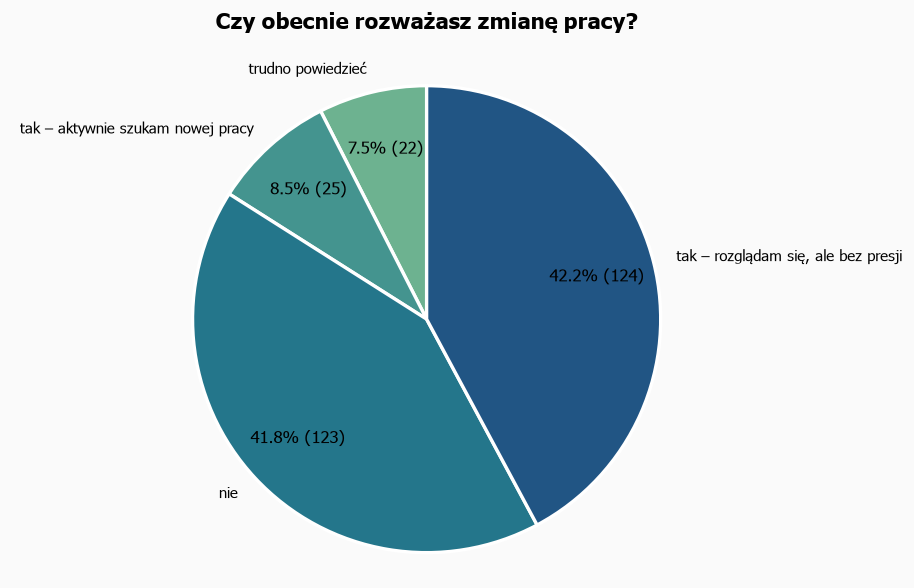

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.pie(
    df_zmiana_pracy['liczba_odpowiedzi'],
    labels=df_zmiana_pracy['czy obecnie rozważasz zmianę pracy'],
    autopct=lambda p: f'{p:.1f}% ({p/100*df_zmiana_pracy["liczba_odpowiedzi"].sum():.0f})',
    startangle=90,
    colors=get_colors(len(df_zmiana_pracy)),
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    pctdistance=0.75
)

ax.set_title('Czy obecnie rozważasz zmianę pracy?', pad=20)

ax.axis('equal')
plt.tight_layout()
plt.show()

Spośród 294 respondentów, którzy udzielili odpowiedzi na pytanie o rozważanie zmiany pracy, 50,7% deklaruje, że bierze pod uwagę zmianę pracodawcy (149 osób). W tej grupie 25 osób (8,5% wszystkich odpowiadających) aktywnie poszukuje nowej pracy. Wyniki pokazują, że rozważanie zmiany zatrudnienia jest w badanej grupie dość powszechne.

### Jakie czynniki najczęściej skłaniają respondentów do rozważania zmiany pracodawcy?

In [32]:
#Przygotowanie danych
kolumny_powodow = df_przyszlosc.filter(
    regex='^zmiana pracy \\|'
).columns.tolist()

df_powody_zmiany = df_przyszlosc[
    df_przyszlosc['czy obecnie rozważasz zmianę pracy']
    .str.startswith('tak', na=False)
][kolumny_powodow].melt(
    var_name='powod_zmiany',
    value_name='wskazanie'
)

df_powody_zmiany = (
    df_powody_zmiany
    .groupby('powod_zmiany')['wskazanie']
    .sum()
    .reset_index(name='liczba_wskazan')
    .sort_values('liczba_wskazan', ascending=True)
)

df_powody_zmiany['powod_zmiany'] = (
    df_powody_zmiany['powod_zmiany']
    .str.replace('zmiana pracy | ', '', regex=False)
)

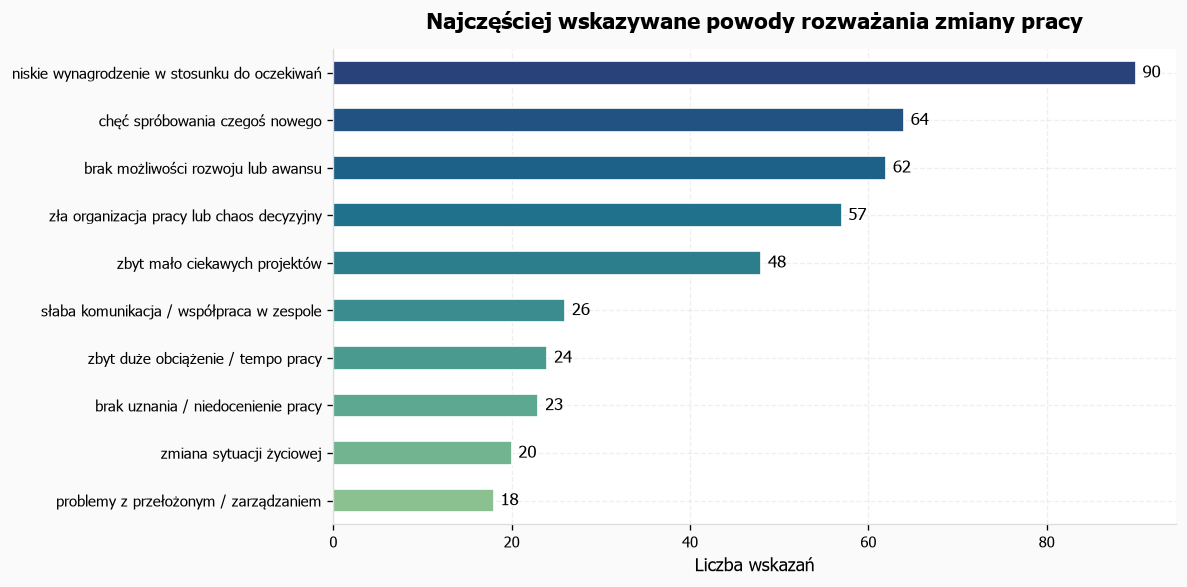

In [33]:
#Wykres
fig, ax = plt.subplots(figsize=(10, 5))

df_powody_zmiany.plot(
    kind='barh',
    x='powod_zmiany',
    y='liczba_wskazan',
    ax=ax,
    color=get_colors(len(df_powody_zmiany)),
    edgecolor='white',
    legend=False
)

ax.set_title('Najczęściej wskazywane powody rozważania zmiany pracy')
ax.set_xlabel('Liczba wskazań')
ax.set_ylabel('')

ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    padding=4
)

plt.tight_layout()
plt.show()

Najczęściej wskazywanym powodem rozważania zmiany pracy jest niskie wynagrodzenie w stosunku do oczekiwań. Kolejne często wymieniane odpowiedzi to chęć spróbowania czegoś nowego oraz brak możliwości rozwoju lub awansu. Wśród istotnych wskazań pojawiają się również zła organizacja pracy lub chaos decyzyjny oraz niewystarczająca liczba ciekawych projektów.

Wyniki sugerują, że kwestie finansowe są ważnym aspektem rozważania zmiany pracodawcy. Jednocześnie respondenci zwracają uwagę na potrzebę rozwoju zawodowego, różnorodności zadań i udziału w interesujących projektach.

### Czy odsetek respondentów rozważających zmianę pracy różni się w zależności od poziomu stanowiska?

In [34]:
#Przygotowanie danych
df_odsetek_zmiany = (
    df_analiza
    .dropna(subset=[
        'poziom stanowiska (seniority)',
        'czy obecnie rozważasz zmianę pracy'
    ])
    .groupby('poziom stanowiska (seniority)')
    .agg(
        liczba_respondentow=('rozważa_zmianę', 'size'),
        liczba_rozważających=('rozważa_zmianę', 'sum')
    )
    .reset_index()
)

df_odsetek_zmiany['odsetek_zmiany'] = (
    df_odsetek_zmiany['liczba_rozważających']
    / df_odsetek_zmiany['liczba_respondentow']
    * 100
)

df_odsetek_zmiany = df_odsetek_zmiany.sort_values(
    'odsetek_zmiany',
    ascending=True
)

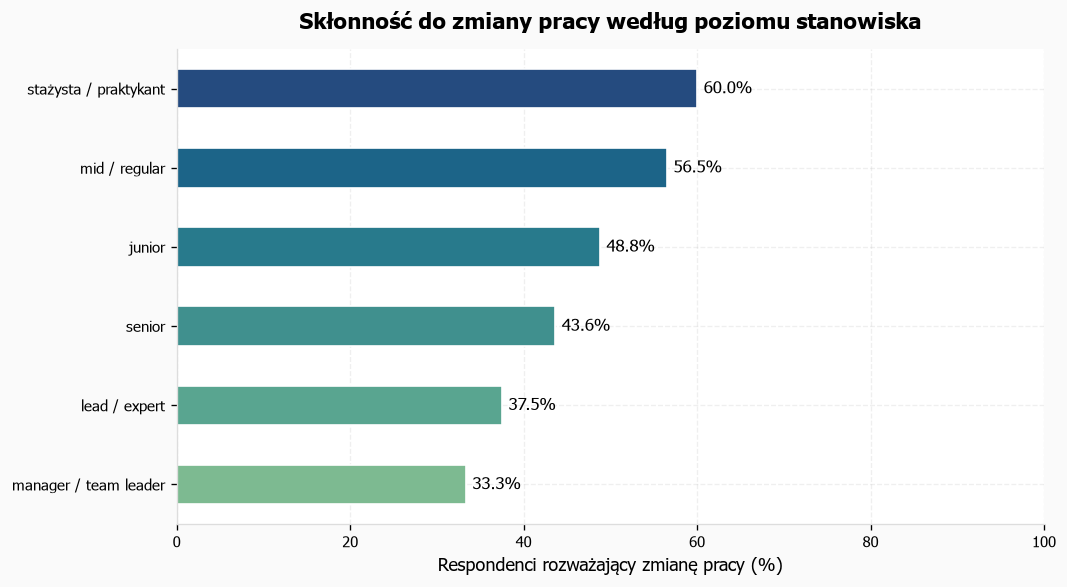

In [35]:
#Wykres
fig, ax = plt.subplots(figsize=(9, 5))

df_odsetek_zmiany.plot(
    kind='barh',
    x='poziom stanowiska (seniority)',
    y='odsetek_zmiany',
    ax=ax,
    color=get_colors(len(df_odsetek_zmiany)),
    edgecolor='white',
    legend=False
)

ax.set_title('Skłonność do zmiany pracy według poziomu stanowiska')
ax.set_xlabel('Respondenci rozważający zmianę pracy (%)')
ax.set_ylabel('')
ax.set_xlim(0, 100)

ax.bar_label(
    ax.containers[0],
    fmt='%.1f%%',
    padding=4
)

plt.tight_layout()
plt.show()

Najwyższy odsetek osób rozważających zmianę pracy występuje wśród stażystów i praktykantów (60%) oraz osób na poziomie mid/regular (56,5%). Wśród juniorów odsetek ten wynosi 48,8%. W przedstawionych wynikach widoczna jest tendencja do niższej skłonności do zmiany pracy na wyższych poziomach stanowisk.

Może to wskazywać, że poziom doświadczenia zawodowego wiąże się ze skłonnością do poszukiwania nowych możliwości. Należy jednak pamiętać, że liczebność poszczególnych grup może być różna.

### Ocena rynku pracy a skłonność do zmiany

In [36]:
#Wyliczenie średniej ocen obecnego rynku pracy w branży data/it
avg_it_branch = df_przyszlosc['jak oceniasz obecny rynek pracy w branży data / it'].mean().round(2)
print('Średnia ocena obecnego rynku pracy w branży data/it: ',avg_it_branch)

#Wyliczenie średniej ocen obecnego rynku pracy w branży data/it w zależności od chęci zmiany pracy u respondentów
df_avg_ocena_rynku = (
    df_przyszlosc
    .groupby('czy obecnie rozważasz zmianę pracy')['jak oceniasz obecny rynek pracy w branży data / it']
    .mean()
    .round(2)
    .reset_index(name='średnia_ocen')
    .sort_values('średnia_ocen',ascending=True)
)

Średnia ocena obecnego rynku pracy w branży data/it:  5.14


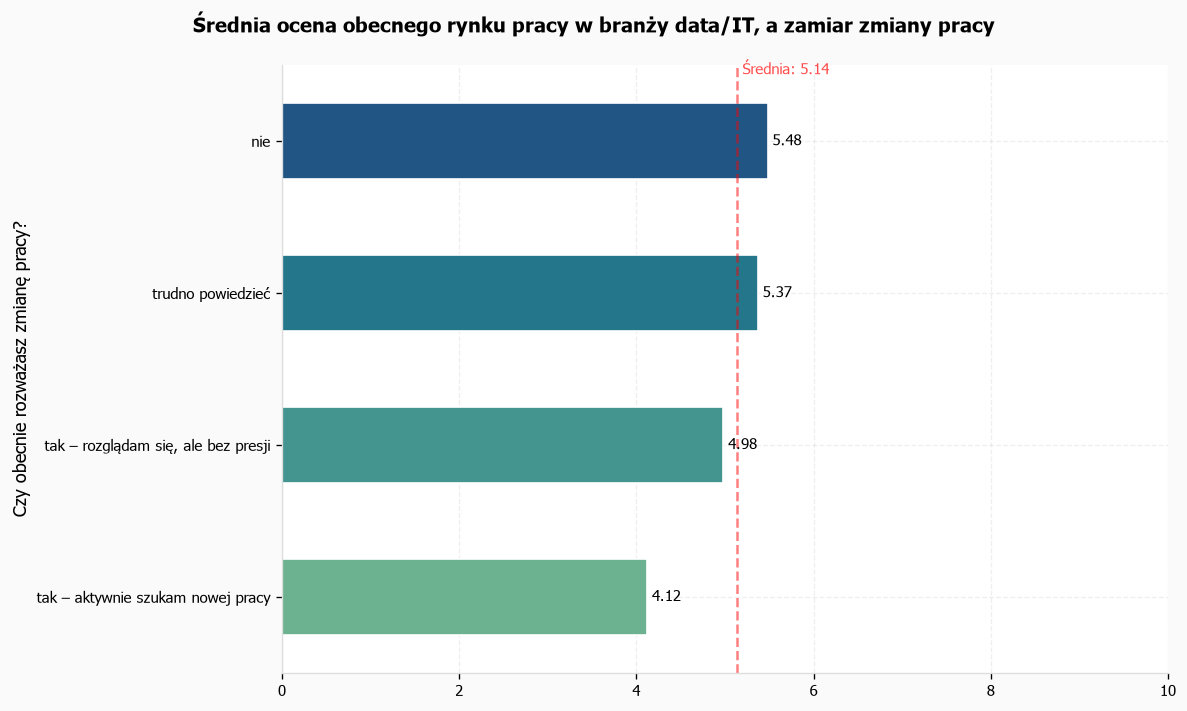

In [37]:
#Wykres
fig,ax = plt.subplots(figsize=(10,6))

df_avg_ocena_rynku.plot(
    kind='barh',
    ax=ax,
    x='czy obecnie rozważasz zmianę pracy',
    y='średnia_ocen',
    color=get_colors(len(df_avg_ocena_rynku)),
    edgecolor='white',
    legend=False
)
ax.axvline(
    x=avg_it_branch,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Średnia ogólna: {avg_it_branch:.2f}',
    alpha=0.5
)
ax.text(
    avg_it_branch,
    0.98,
    f' Średnia: {avg_it_branch:.2f}',
    transform=ax.get_xaxis_transform(),
    color='red',
    alpha=0.7,
    ha='left',
    va='bottom',
    fontsize=9
)
ax.bar_label(
    ax.containers[0],
    fmt='%.2f',    
    label_type='edge', # umieszczenie etykiet na krawędzi słupków
    padding=3,
    fontsize=9 
)
plt.suptitle('Średnia ocena obecnego rynku pracy w branży data/IT, a zamiar zmiany pracy',x=0.5,ha='center',fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Czy obecnie rozważasz zmianę pracy?')
ax.set_xlim(0, 10)

plt.tight_layout()
plt.show()

Średnia ocena obecnego rynku pracy w branży data/IT wśród wszystkich respondentów wynosi **5,14** w skali od 1 do 10. 
Osoby aktywnie poszukujące nowej pracy oceniają rynek najniżej — średnio na **4,12**. 
W grupie osób rozważających zmianę, ale nieposzukujących aktywnie, średnia wynosi 4,98.

Wyniki wskazują, że osoby bardziej zdecydowane na zmianę zatrudnienia mają mniej pozytywną ocenę obecnej sytuacji na rynku pracy. Może to współwystępować z ich doświadczeniami zawodowymi lub oczekiwaniami wobec rynku.

### Ocena przyszłości branży a skłonność do zmiany

In [38]:
#Wyliczenie średniej oceny przyszłości branży data/it
avg_it_branch_future = df_przyszlosc['jak oceniasz przyszłość branży data / it'].mean().round(2)
print('Średnia ocena przyszłości branży data/it: ',avg_it_branch_future)


#Wyliczenie średniej oceny przyszłości branży data/it w zależności od chęci zmiany pracy u respondentów
df_avg_ocena_przyszlosci_rynku = (
    df_przyszlosc
    .groupby('czy obecnie rozważasz zmianę pracy')['jak oceniasz przyszłość branży data / it']
    .mean()
    .round(2)
    .reset_index(name='średnia_ocen')
    .sort_values('średnia_ocen',ascending=True)
)

Średnia ocena przyszłości branży data/it:  6.29


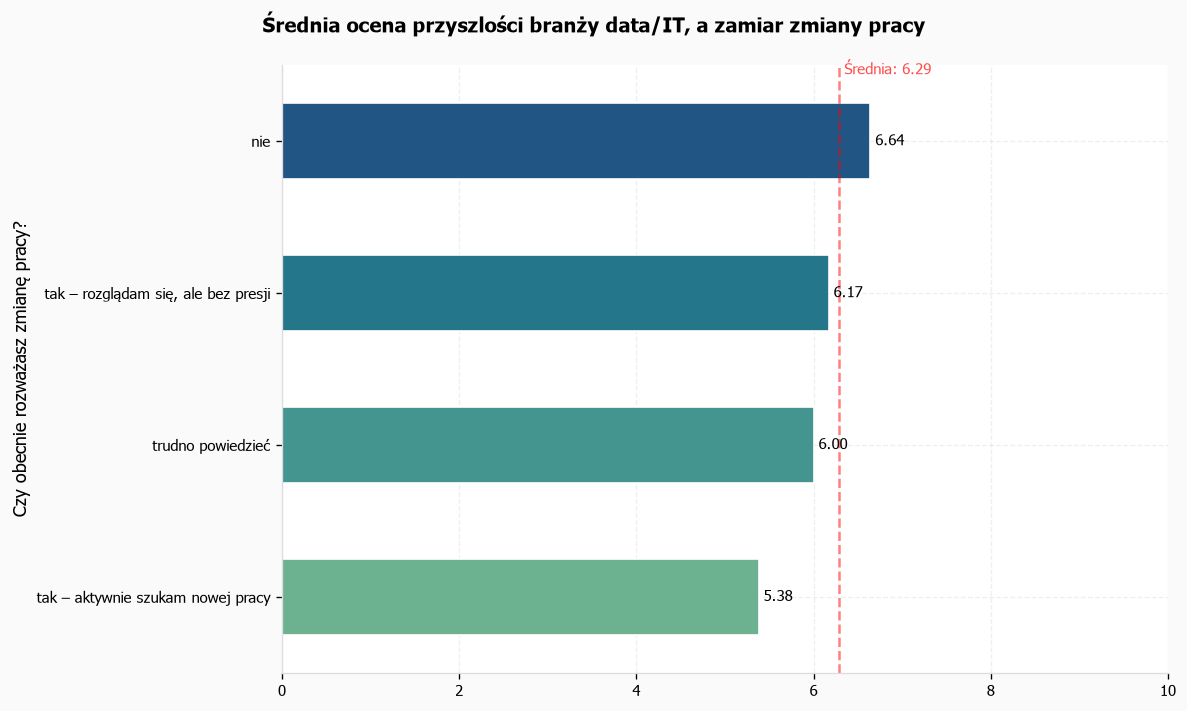

In [39]:
#Wykres
fig,ax = plt.subplots(figsize=(10,6))

df_avg_ocena_przyszlosci_rynku.plot(
    kind='barh',
    ax=ax,
    x='czy obecnie rozważasz zmianę pracy',
    y='średnia_ocen',
    color=get_colors(len(df_avg_ocena_przyszlosci_rynku)),
    edgecolor='white',
    legend=False
)
ax.axvline(
    x=avg_it_branch_future,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Średnia ogólna: {avg_it_branch_future:.2f}',
    alpha=0.5
)
ax.text(
    avg_it_branch_future,
    0.98,
    f' Średnia: {avg_it_branch_future:.2f}',
    transform=ax.get_xaxis_transform(),
    color='red',
    alpha=0.7,
    ha='left',
    va='bottom',
    fontsize=9
)
ax.bar_label(
    ax.containers[0],
    fmt='%.2f',    
    label_type='edge', # umieszczenie etykiet na krawędzi słupków
    padding=3,
    fontsize=9 
)
plt.suptitle('Średnia ocena przyszlości branży data/IT, a zamiar zmiany pracy',x=0.5,ha='center',fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Czy obecnie rozważasz zmianę pracy?')
ax.set_xlim(0, 10)
#ax.get_xaxis().set_visible(False)  # Ukrycie osi X i jej elementów

plt.tight_layout()
plt.show()

Średnia ocena przyszłości branży data/IT wśród wszystkich respondentów wynosi **6,29**. Osoby aktywnie poszukujące nowej pracy oceniają ją niżej — **średnio na 5,38**.

Może to wskazywać, że osoby aktywnie rozważające zmianę zatrudnienia są również bardziej sceptyczne wobec przyszłości branży.

### Czy poziom wynagrodzenia wiąże się ze skłonnością do zmiany pracy?

In [40]:
#Sprawdzenie danych dot. zarobków
print(df_analiza['zarobki'].dtype)
print(df_analiza['zarobki'].value_counts(dropna=False))

float64
zarobki
NaN        30
10000.0    17
7000.0     14
8000.0     13
5000.0     12
           ..
25000.0     1
5100.0      1
11400.0     1
19000.0     1
13800.0     1
Name: count, Length: 89, dtype: int64


In [41]:
#Przygotowanie danych
df_zarobki = (
    df_analiza
    .dropna(subset=['zarobki', 'czy obecnie rozważasz zmianę pracy'])
    .groupby('rozważa_zmianę')['zarobki']
    .agg(
        liczba_osob='count',
        srednia='mean',
        mediana='median',
        minimum='min',
        maksimum='max'
    )
    .reset_index()
)

df_zarobki['rozważa_zmianę'] = df_zarobki['rozważa_zmianę'].map({
    True: 'Rozważa zmianę',
    False: 'Nie rozważa zmiany'
})

df_zarobki.round(0)

,rozważa_zmianę,liczba_osob,srednia,mediana,minimum,maksimum
0,Nie rozważa zmiany,128,10479.0,9050.0,3834.0,31000.0
1,Rozważa zmianę,138,8524.0,7500.0,4300.0,22000.0


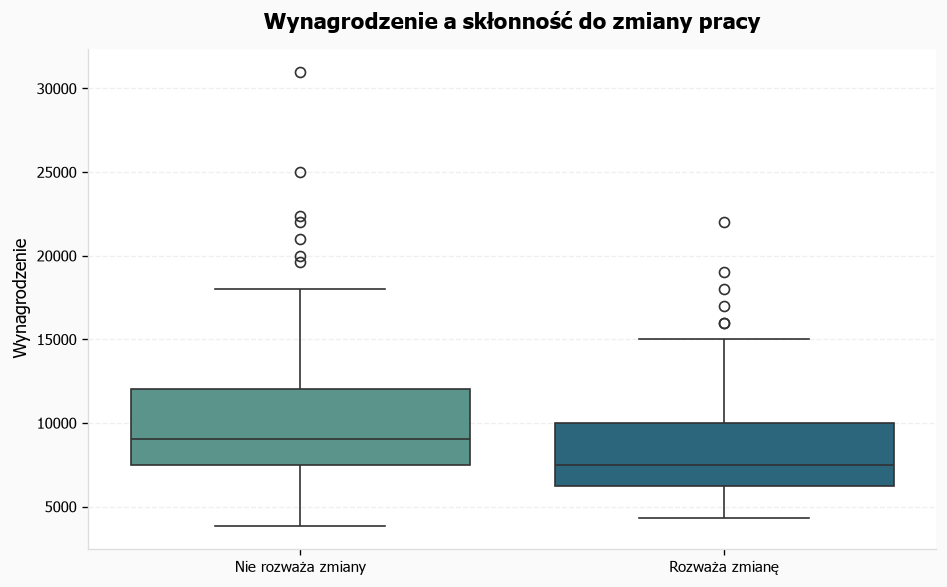

In [42]:
#Wykres
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df_analiza.dropna(
        subset=['zarobki', 'czy obecnie rozważasz zmianę pracy']
    ).assign(
        grupa=lambda x: x['rozważa_zmianę'].map({
            True: 'Rozważa zmianę',
            False: 'Nie rozważa zmiany'
        })
    ),
    x='grupa',
    y='zarobki',
    hue='grupa',
    palette=get_colors(2),
    legend=False,
    ax=ax
)

ax.set_title('Wynagrodzenie a skłonność do zmiany pracy')
ax.set_xlabel('')
ax.set_ylabel('Wynagrodzenie')

plt.tight_layout()
plt.show()

W badanej grupie osoby rozważające zmianę pracy osiągają niższe wynagrodzenia niż osoby, które nie rozważają zmiany. Średnia wynosi odpowiednio 8 524 zł i 10 479 zł, natomiast mediana 7 500 zł i 9 050 zł.

**Różnica median wynosi 1 550 zł**. Wyniki wskazują, że niższe wynagrodzenia współwystępują z częstszym rozważaniem zmiany pracy. Może to sugerować, że poziom wynagrodzenia jest jednym z ważnych aspektów związanych z mobilnością zawodową respondentów.

Analiza obejmuje 266 osób, dla których dostępne były dane o wynagrodzeniu i odpowiedź na pytanie o rozważanie zmiany pracy.

## Podsumowanie analizy
Przeprowadzona analiza pozwoliła przyjrzeć się skłonności do zmiany pracy wśród osób pracujących w branży data/IT oraz czynnikom, które współwystępują z taką deklaracją.

1. Spośród 294 respondentów, którzy odpowiedzieli na pytanie o zmianę pracy, **149 osób (50,7%) zadeklarowało, że ją rozważa. Jedynie 25 osób aktywnie poszukuje nowej pracy**. Oznacza to, że zainteresowanie zmianą pracodawcy jest dość powszechne, ale często ma charakter niezobowiązującego rozglądania się za nowymi możliwościami.

2. Najważniejszym deklarowanym powodem rozważania zmiany pracy jest wynagrodzenie.Na kolejnych miejscach znalazły się chęć spróbowania czegoś nowego oraz brak możliwości rozwoju lub awansu. Istotne okazały się również organizacja pracy i dostępność ciekawych projektów. Pokazuje to, że poza kwestiami finansowymi respondenci zwracają uwagę na możliwości rozwoju i charakter wykonywanych obowiązków.

3. Skłonność do zmiany pracy różni się w zależności od poziomu stanowiska. W przedstawionych wynikach wyższy odsetek osób rozważających zmianę występuje na niższych poziomach stanowisk. Może to wskazywać na większą gotowość do poszukiwania nowych możliwości na wcześniejszych etapach kariery zawodowej.

4. Osoby aktywnie poszukujące pracy gorzej oceniają obecną sytuację na rynku data/IT. **Średnia ocena obecnego rynku wśród wszystkich respondentów wynosi 5,14, natomiast wśród osób aktywnie poszukujących pracy 4,12**. W grupie osób rozważających zmianę, ale nieposzukujących aktywnie, średnia wynosi 4,98. Wyniki sugerują związek między sposobem postrzegania rynku pracy a gotowością do zmiany zatrudnienia.

5. Podobna tendencja widoczna jest w ocenie przyszłości branży. **Średnia ocena przyszłości branży wynosi 6,29, natomiast osoby aktywnie poszukujące pracy oceniają ją na 5,38**. Może to świadczyć o większym sceptycyzmie tej grupy wobec perspektyw branży data/IT.

6. Wynagrodzenie wiąże się ze skłonnością do zmiany pracy. Osoby rozważające zmianę osiągają niższe wynagrodzenia niż respondenci nierozważający takiej zmiany. Mediana wynagrodzenia wynosi odpowiednio 7 500 zł i 9 050 zł. Jest to jedna z wyraźniejszych różnic zaobserwowanych w analizie.


Analiza ma charakter eksploracyjny i opiera się na deklaracjach ankietowanych. Nie pozwala określić bezpośrednich przyczyn decyzji o zmianie pracy ani uogólniać wyników na wszystkie osoby pracujące w branży data/IT. Pokazuje jednak interesujące tendencje i zależności, które mogą stanowić punkt wyjścia do dalszej analizy rynku pracy.